In [1]:
import uproot
import pandas
import numpy as np
import os

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt\
  
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import interp1d

uproot.__version__

'5.0.8'

<!-- <img src="../data/morozov_2010_spectrum.png" alt="photo_morozov_2010_spectrum" width="300"> -->
<!-- <img src="../data/morozov_UV_yields.png" alt="photo_morozov_UV_yields" width="300"> -->

<div style="display:flex">
  <img src="../data_scintillation/morozov_2010_spectrum.png" alt="photo_morozov_2010_spectrum" width="500">
  <img src="../data_scintillation/morozov_UV_yields.png" alt="photo_morozov_UV_yields" width="500">
</div>


In [2]:
## loading the data ##
# Define the folder path
opticsPath_g4 = "../g4PDEsim/dataOptics/"
scintPath_g4 = "../g4PDEsim/data_cf4_scint/"
opticsPath = "../data_allOptics/"
dataPath = "../data_scintillation/"
savePath = "./dataOutputs/"

In [3]:
## loading all scintillation data ##

if os.path.exists(file_path := os.path.join(scintPath_g4, "cf4Scint_1bar_all.txt")):
  print(file_path, "exists")

## all morozov data
xMoroz1Bar, yMoroz1Bar = np.loadtxt(os.path.join(scintPath_g4, "cf4Scint_1bar_all.txt"), unpack=True, skiprows=1)
xt, yt = np.loadtxt(os.path.join(scintPath_g4, "cf4Scint_5bar_Vis.txt"), unpack=True, skiprows=1)
xt2, yt2 = np.loadtxt(os.path.join(scintPath_g4, "cf4Scint_5bar_UV.txt"), unpack=True, skiprows=1)
xMoroz5Bar = np.concatenate((xt2, xt))
yMoroz5Bar = np.concatenate((yt2, yt))

##-- listing UV yields and max values from spectrum --##
# uvYields, 0.5 bar, from Morozov
lyUV_moroz05bar = 2280. # from table. stops at 200nm
lyUV_moroz1bar = (2150+1980)/2. # from table. stops at 200nm

# uv 5 bar yields, from Morozov
ly1 = [707, 858-707] # two measurements, weighted average by errors
ly2 = [665, 777-665] # values taken from webPlotDigitizer (tables in data folder)
etot = ly1[1] + ly2[1]
lyUV_moroz5bar = (ly1[0]*(ly1[1]/etot)  + ly2[0]*ly2[1]/etot) # do weighted average
# print(lyUV_moroz5bar)

# max heights
vis_max5bar = 33.5 # ph/MeV nm, from inspecting the graph
uv_max5bar = 7. # ph/MeV nm, from inspecting the graph
uv_max1bar = 23.5 # ph/MeV nm, from inspecting the graph

# scaling Morozov data (which is in AU)
yMoroz1Bar *= (uv_max1bar/max(yMoroz1Bar))
yMoroz5Bar *= (vis_max5bar/max(yMoroz5Bar))

##-- deep UV component --##
xGernCf4, yGernCf4 = np.loadtxt(os.path.join(dataPath, "gernhauser_cf4_05bar_spikes.csv"), delimiter=',', skiprows=1, unpack=True)
xGernCf4Smooth, yGernCf4Smooth = np.loadtxt(os.path.join(dataPath, "gernhauser_cf4_05bar.csv"), delimiter=',', skiprows=1, unpack=True)
xGernCf4 = xGernCf4Smooth # use non-spikey data (spikes are contamination)
yGernCf4 = yGernCf4Smooth

gern_sort = np.argsort(xGernCf4)
xGernCf4_sorted = xGernCf4[gern_sort]
yGernCf4_sorted = yGernCf4[gern_sort]
# yGernCf4_sorted_smoother = scipy.ndimage.uniform_filter1d(yGernCf4_sorted, size= 10) # smoothing. not needed

## now scale data (which is in AU) to ly/MeV using max values from above
# morozov defines UV as below 500nm
# scaling Gern to match Moroz from 200nm to 320nm (end of Gern)

# first scale Moroz 1 bar data to the 0.5 bar LY
intensity1 = scipy.integrate.simps(yMoroz1Bar[np.where(xMoroz1Bar<500)], xMoroz1Bar[np.where(xMoroz1Bar<500)])
yMoroz05Bar = yMoroz1Bar * (lyUV_moroz05bar/intensity1)
print((lyUV_moroz05bar/intensity1))
print(lyUV_moroz05bar/lyUV_moroz1bar) # should be close to eachother (10% dif from 1bar to 0.5bar given in paper)

xMoroz05Bar = xMoroz1Bar

# now scale Gern in that region to match Moroz 0.5 bar
# they overlap between min(xMoroz05Bar) ~220nm, and max(xGernCf4_sorted) ~320nm
# mask = (x >= min(xMoroz05Bar)) & (x <= max(xGernCf4_sorted))
# x_selected = x[mask]
# y_selected = y[mask]

intensityMoroz_restrictedArea = scipy.integrate.simps(yMoroz05Bar[np.where( xMoroz05Bar < max(xGernCf4_sorted))], xMoroz05Bar[np.where(xMoroz05Bar < max(xGernCf4_sorted))])
intensityGern_restrictedArea = scipy.integrate.simps(yGernCf4_sorted[np.where( xGernCf4_sorted > min(xMoroz05Bar))], xGernCf4_sorted[np.where( xGernCf4_sorted > min(xMoroz05Bar))])

scaledGernY = yGernCf4_sorted * (intensityMoroz_restrictedArea/intensityGern_restrictedArea)


../g4PDEsim/data_cf4_scint/cf4Scint_1bar_all.txt exists
1.1015865674249306
1.1041162227602905


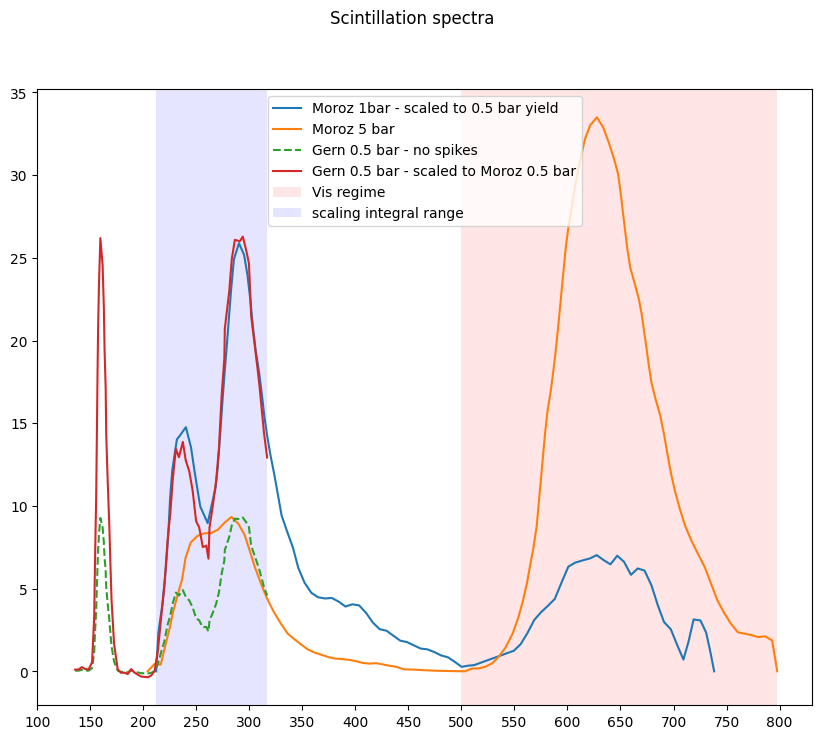

In [4]:
fig, (ax1) = plt.subplots(1, 1, figsize=(10, 8))
fig.suptitle("Scintillation spectra")  # Add the title at the top of the figure

ax1.plot(xMoroz05Bar, yMoroz05Bar, label="Moroz 1bar - scaled to 0.5 bar yield")
ax1.plot(xMoroz5Bar, yMoroz5Bar, label="Moroz 5 bar")

ax1.plot(xGernCf4_sorted, yGernCf4_sorted, linestyle="--", label="Gern 0.5 bar - no spikes")

ax1.plot(xGernCf4_sorted, scaledGernY, linestyle="-", label="Gern 0.5 bar - scaled to Moroz 0.5 bar")

ax1.axvspan(500, max(xMoroz5Bar), facecolor='red', alpha=0.1, label = "Vis regime")

ax1.axvspan(min(xMoroz05Bar), max(xGernCf4_sorted), facecolor='blue', alpha=0.1, label = "scaling integral range")

ax1.legend(loc="upper center")  # Place the legend in the top right corner

# Add tick marks starting at 100nm and going up every 50
ax1.set_xticks(np.arange(100, 850, 50))

plt.show()

vis 5bar yield 3650.449237670616
no Gern UV LY =  2280.0
with Gern UV yeild =  2552.907219167992


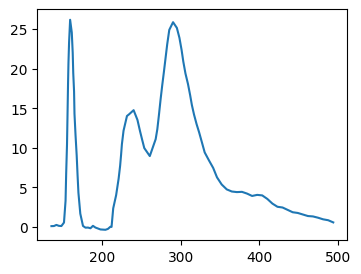

In [5]:
## now calculate total 'scaled' 0.5 bar yield
fullUVSpectrum = np.append(scaledGernY[np.where(xGernCf4_sorted < min(xMoroz05Bar))], yMoroz05Bar[np.where((xMoroz05Bar < 500))])
fullUV_wls = np.append(xGernCf4_sorted[np.where(xGernCf4_sorted < min(xMoroz05Bar))], xMoroz05Bar[np.where((xMoroz05Bar < 500))])

visYield5bar = scipy.integrate.simps(yMoroz5Bar[np.where( xMoroz5Bar > 500)], xMoroz5Bar[np.where( xMoroz5Bar > 500)])
print("vis 5bar yield", visYield5bar)
fullUVYield = scipy.integrate.simps(fullUVSpectrum, fullUV_wls)
print("no Gern UV LY = ", lyUV_moroz05bar)
print("with Gern UV yeild = ", fullUVYield)

plt.figure(figsize=(4, 3))
plt.plot(fullUV_wls, fullUVSpectrum)
plt.show()


---
### Refractive Indices

In [6]:
## Silicon n and k
si_x_n_amorphous, si_y_n_amorphous = np.loadtxt(os.path.join(opticsPath, "siliconRINDEX_100nm_Pierce.txt"), skiprows=1, unpack = True)
si_x_n_amorphous *= 1000
si_x_k_amorphous, si_y_k_amorphous = np.loadtxt(os.path.join(opticsPath, "siliconKINDEX_100nm_Pierce.txt"), skiprows=1, unpack = True)
si_x_k_amorphous *= 1000

si_x_n_crystal, si_y_n_crystal = np.loadtxt(os.path.join(opticsPath, "silicon_N_Aspnes.txt"), skiprows=1, unpack = True)
si_x_k_crystal, si_y_k_crystal = np.loadtxt(os.path.join(opticsPath, "silicon_K_Aspnes.txt"), skiprows=1, unpack = True)
si_x_n_crystal *= 1000
si_x_k_crystal *= 1000

## SiO2 n and k
sioX, sioN, sioK = np.loadtxt(os.path.join(opticsPath, "sio2-fusedQuartz_uv_web.txt"), skiprows=1, unpack = True)
sioX2, sioN2, sioK2 = np.loadtxt(os.path.join(opticsPath, "sio2-fusedQuartz_vuv_web.txt"), skiprows=1, unpack = True)
sioX_ri, sioN_ri = np.loadtxt(os.path.join(opticsPath, "sio2_refInfo_malitson.txt"), skiprows=1, unpack = True)
sioX_ri *= 1000

def nsio2_web(wl):
  x = wl/1000
  n=(1 + 0.6961663/(1-(0.0684043/x)**2)+0.4079426/(1-(0.1162414/x)**2)+ 0.8974794/(1-(9.896161/x)**2)) **.5
  return n

g4sio2X, g4sio2N = np.loadtxt(os.path.join(opticsPath, "g4_sio2_rindex.txt"), skiprows=1, unpack = True)
g4sio2X = 1240/(g4sio2X*1e6)

print(max(sioX), max(sioX2), max(sioX_ri), max(g4sio2X))

800.0 800.0 6700.0 6700.855439851717


savePath ./dataOutputs/


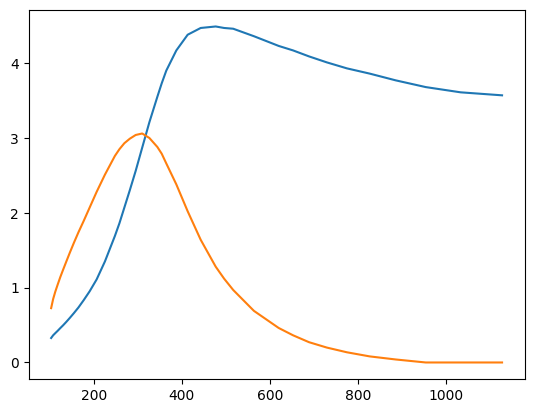

In [7]:
# plt.plot(si_x_n_amorphous, si_y_n_amorphous)
# # plt.vlines(0, 5, 100)
# plt.xlim(100, 200)

si_n_amorphous_truncated = si_y_n_amorphous[np.where(si_x_n_amorphous <= 1200)]
si_k_amorphous_truncated = si_y_k_amorphous[np.where(si_x_k_amorphous <= 1200)]

si_x_n_amorphous_truncated = si_x_n_amorphous[np.where(si_x_n_amorphous <= 1200)]
si_x_k_amorphous_truncated = si_x_k_amorphous[np.where(si_x_k_amorphous <= 1200)]

print("savePath", savePath)
np.savetxt(os.path.join(savePath, 'si_n_amorphous.txt'), np.column_stack((si_x_n_amorphous_truncated, si_n_amorphous_truncated)), fmt='%f', delimiter='\t', header="wavelength (nm), n - amorphous data truncated")
np.savetxt(os.path.join(savePath, 'si_k_amorphous.txt'), np.column_stack((si_x_k_amorphous_truncated, si_k_amorphous_truncated)), fmt='%f', delimiter='\t', header="wavelength (nm), k - amorphous data truncated")

plt.plot(si_x_n_amorphous_truncated, si_n_amorphous_truncated)
plt.plot(si_x_k_amorphous_truncated, si_k_amorphous_truncated)

# resaving the amorphous data in nm
# np.savetxt(os.path.join(savePath,'sio2_n_merged.txt'), np.column_stack((sio_n_x_total, sio_n_y_total)), fmt='%f', delimiter='\t', header = "wavelength (nm), n - data merged from lithography webpage and Malitson")
# np.savetxt(os.path.join(savePath,'sio2_k_merged.txt'), np.column_stack((sio_k_x_total, sio_k_y_total)), fmt='%f', delimiter='\t', header = "wavelength (nm), k - data from lithography webpage (UV)")

In [8]:
## merge SiO2 data at high wavelength

sio_n_x_total = np.append(sioX, sioX_ri[np.where((sioX_ri > max(sioX)) & (sioX_ri < 1200))])
sio_n_y_total = np.append(sioN, sioN_ri[np.where((sioX_ri > max(sioX)) & (sioX_ri < 1200))])

specialKmask = list(np.where(sioK > 0)[0])
print(specialKmask)
specialKmask.append((max(specialKmask) + 1))

sio_k_x_total = np.copy(sioX[specialKmask])
sio_k_y_total = np.copy(sioK[specialKmask])

sio_n_xEV = 1240./(np.copy(sio_n_x_total[::-1]))
sio_n_yEV = np.copy(sio_n_y_total[::-1])

sio_k_xEV = 1240./(np.copy(sio_k_x_total[::-1]))
sio_k_yEV = np.copy(sio_k_y_total[::-1])

np.savetxt(os.path.join(savePath,'sio2_n_merged.txt'), np.column_stack((sio_n_x_total, sio_n_y_total)), fmt='%f', delimiter='\t', header = "wavelength (nm), n - data merged from lithography webpage and Malitson")
np.savetxt(os.path.join(savePath,'sio2_k_merged.txt'), np.column_stack((sio_k_x_total, sio_k_y_total)), fmt='%f', delimiter='\t', header = "wavelength (nm), k - data from lithography webpage (UV)")

np.savetxt(os.path.join(savePath,'sio2_n_eV.txt'), np.column_stack((sio_n_xEV, sio_n_yEV)), fmt='%f', delimiter='\t', header = "eV, n - data merged from lithography webpage and Malitson")
np.savetxt(os.path.join(savePath,'sio2_k_eV.txt'), np.column_stack((sio_k_xEV, sio_k_yEV)), fmt='%f', delimiter='\t', header = "eV, k - data from lithography webpage (UV)")

[0, 1, 2, 3, 4, 5, 6, 7, 8]


In [9]:
## do Silicon merging at low and high WL ##
jumpToAmorphous = 900
endRange = 1200
si_x_n_total = np.append(si_x_n_amorphous[np.where(si_x_n_amorphous<min(si_x_n_crystal))], si_x_n_crystal) # adding front
si_x_n_total = np.append(si_x_n_total, si_x_n_amorphous[np.where((si_x_n_amorphous > jumpToAmorphous) & (si_x_n_amorphous < endRange))]) # adding back

si_y_n_total = np.append(si_y_n_amorphous[np.where(si_x_n_amorphous<min(si_x_n_crystal))], si_y_n_crystal)
si_y_n_total = np.append(si_y_n_total, si_y_n_amorphous[np.where((si_x_n_amorphous > jumpToAmorphous) & (si_x_n_amorphous < endRange))])

si_x_k_total = np.append(si_x_k_amorphous[np.where(si_x_k_amorphous<min(si_x_k_crystal))], si_x_k_crystal)
si_x_k_total = np.append(si_x_k_total, si_x_k_amorphous[np.where((si_x_k_amorphous > jumpToAmorphous) & (si_x_k_amorphous < endRange))])

si_y_k_total = np.append(si_y_k_amorphous[np.where(si_x_k_amorphous<min(si_x_k_crystal))], si_y_k_crystal)
si_y_k_total = np.append(si_y_k_total, si_y_k_amorphous[np.where((si_x_k_amorphous > jumpToAmorphous) & (si_x_k_amorphous < endRange))])

# Smooth out the data where x values are below 300
# mask = (si_x_k_total < 300) & (si_x_k_total > 150)
# si_y_k_total_smooth[mask] = scipy.ndimage.gaussian_filter1d(si_y_k_total_smooth[mask], sigma=2)


# Smooth out the data where x values are below 300
# mask = (si_x_n_total < 300) & (si_x_n_total > 150)
# print(mask)
# si_y_n_total_smooth[mask] = scipy.ndimage.gaussian_filter1d(si_y_n_total_smooth[mask], sigma=2)

nendSmoothMask = np.where((si_x_n_total > 750) & (si_x_n_total < 900))
kendSmoothMask = np.where(si_x_k_total > 750)

nfrontMask = np.where((si_x_n_total > min(si_x_n_crystal) - 20) & (si_x_n_total < min(si_x_n_crystal) + 20))

si_y_n_smoothed = si_y_n_total.copy()
si_y_n_smoothed[nendSmoothMask] = gaussian_filter1d(si_y_n_smoothed[nendSmoothMask], sigma = 10)
si_y_n_smoothed[nfrontMask] = gaussian_filter1d(si_y_n_smoothed[nfrontMask], sigma = 1)

si_y_k_smoothed = si_y_k_total.copy()
si_y_k_smoothed[kendSmoothMask] = gaussian_filter1d(si_y_k_smoothed[kendSmoothMask], sigma = 2)

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_47475/2919527486.py:20: RuntimeWarning: invalid value encountered in sqrt
  n=(1 + 0.6961663/(1-(0.0684043/x)**2)+0.4079426/(1-(0.1162414/x)**2)+ 0.8974794/(1-(9.896161/x)**2)) **.5


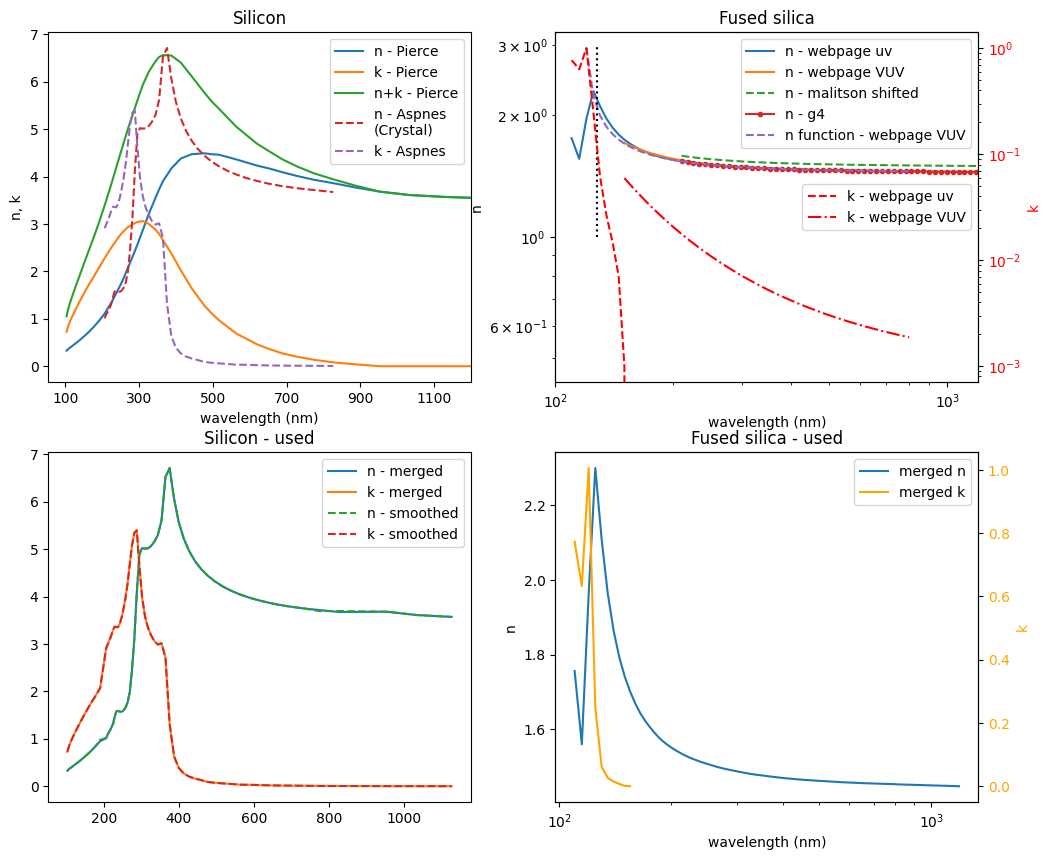

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
minWl = 100
maxWl = 1200

###---- silicon ----###
ax[0, 0].set_title("Silicon")
ax[0, 0].plot(si_x_n_amorphous, si_y_n_amorphous, label="n - Pierce")
ax[0, 0].plot(si_x_k_amorphous, si_y_k_amorphous, label="k - Pierce")
ax[0, 0].plot(si_x_k_amorphous, si_y_n_amorphous+si_y_k_amorphous, label="n+k - Pierce")

ax[0, 0].plot(si_x_n_crystal, si_y_n_crystal, linestyle = "--", label="n - Aspnes \n(Crystal)")
ax[0, 0].plot(si_x_k_crystal, si_y_k_crystal, linestyle = "--", label="k - Aspnes")

ax[0, 0].set_xlabel("wavelength (nm)")
ax[0, 0].set_ylabel("n, k")
ax[0, 0].legend()
ax[0, 0].set_xticks(np.arange(100, maxWl, 200))
ax[0, 0].set_xlim(min(si_x_n_amorphous)-50, maxWl)

###---- silicon USED ----###
ax[1, 0].set_title("Silicon - used")
ax[1, 0].plot(si_x_n_total, si_y_n_total, linestyle="-", label="n - merged")
ax[1, 0].plot(si_x_k_total, si_y_k_total, linestyle="-", label="k - merged")

ax[1, 0].plot(si_x_n_total, si_y_n_smoothed, linestyle="--", label="n - smoothed")
ax[1, 0].plot(si_x_k_total, si_y_k_smoothed, linestyle="--", label="k - smoothed")
ax[1, 0].legend()

###---- fused silica ----###
ax[0, 1].set_title("Fused silica")

ax[0, 1].loglog(sioX, sioN, label="n - webpage uv")
ax[0, 1].loglog(sioX2, sioN2, label="n - webpage VUV")
ax[0, 1].loglog(sioX_ri, sioN_ri+0.05, linestyle="--", label="n - malitson shifted")
ax[0, 1].loglog(g4sio2X, g4sio2N, marker=".", label="n - g4")

ax[0, 1].loglog(sioX, nsio2_web(sioX), linestyle="--", label="n function - webpage VUV")

ax[0, 1].set_xlim(100, 1200)

ax[0, 1].set_xlabel("wavelength (nm)")
ax[0, 1].set_ylabel("n")

ax2 = ax[0, 1].twinx()
ax2.semilogy(sioX, sioK, linestyle="--", color = "red", label="k - webpage uv")
ax2.semilogy(sioX2, sioK2, linestyle="-.", color = "red", label="k - webpage VUV")

ax2.set_ylabel("k", color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax[0, 1].legend(loc='upper right')
ax2.legend(loc='center right')

ax[0, 1].vlines(128, 1, 3, color="black", linestyle=":", label="9.7 eV")

###---- fused silica USED ----###
ax[1, 1].set_title("Fused silica - used")
ax[1, 1].plot(sio_n_x_total, sio_n_y_total, label = "merged n")
h1, l1 = ax[1, 1].get_legend_handles_labels()

axt = ax[1, 1].twinx()
axt.semilogx(sio_k_x_total, sio_k_y_total, color = "orange", label = "merged k")
handle2, label2 = axt.get_legend_handles_labels()

axt.set_ylabel("k", color='orange')
axt.tick_params(axis='y', labelcolor='orange')

ax[1, 1].legend((h1 + handle2), (l1 + label2), loc='upper right')

ax[1, 1].set_xlabel("wavelength (nm)")
ax[1, 1].set_ylabel("n")


# Show the plot
plt.show()

In [11]:
n_index = np.argmin(np.abs(si_x_n_total - 400))
k_index = np.argmin(np.abs(si_x_k_total - 400))

n_value = si_y_n_total[n_index]
k_value = si_y_k_total[k_index]

print("n value:", n_value)
print("k value:", k_value)


n value: 5.57
k value: 0.387


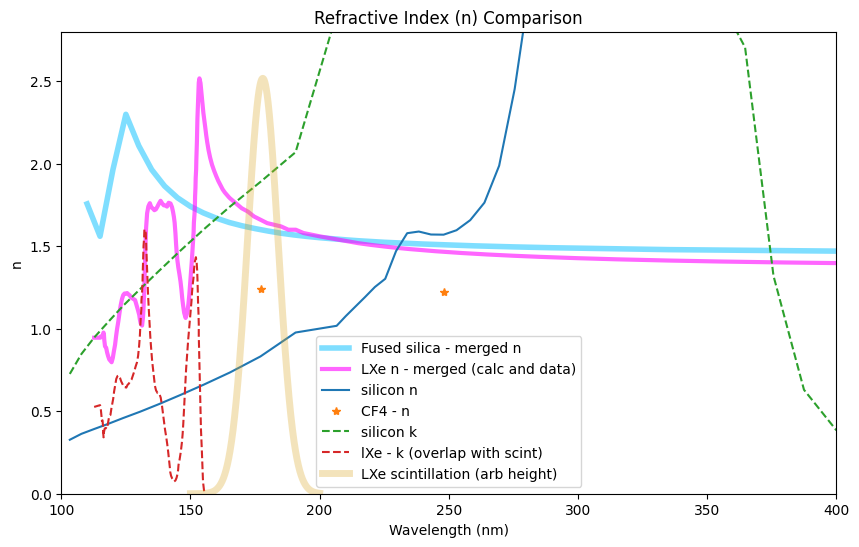

In [12]:
# def refractive_index_xenon(wavelength):
#   # Define the refractive index values for liquid xenon
#   # You can replace these values with the actual data
#   refractive_index = 1.6  # Placeholder value
  
#   # Add your code here to calculate the refractive index based on the wavelength
  
#   return refractive_index
from nobleFunctions import *

rho_lxe = density_t(273-110)

## loading data ##
xe_n_xeV, xe_n_y = np.loadtxt(os.path.join(opticsPath, "LXe-n_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
xe_k_xeV, xe_k_y = np.loadtxt(os.path.join(opticsPath, "LXe-k_vs_Ephoton.txt"), delimiter=",", skiprows=0, unpack = True)
xe_n_x = 1240./xe_n_xeV
xe_k_x = 1240./xe_k_xeV

## CF4 data ## 
cf4_x_n = [7, 5, 2, 1] # energy in eV
cf4_x_n = 1240./np.array(cf4_x_n) # convert to nm
cf4_n = np.array([1.24, 1.225, 1.21, 1.2039])

lxe_wl = np.arange(160, 800, 5)
lxeS_x = np.linspace(150, 200, 1000)
mean = 178  # Mean of the Gaussian
fwhm = 14  # Full Width at Half Maximum (FWHM)
sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))  # Standard deviation of the Gaussian
lxe_y = np.exp(-(lxeS_x - mean)**2 / (2 * sigma**2))

## merging LXe data ##
lxe_newX = np.append(xe_n_x[np.where(xe_n_x < 210)], lxe_wl[np.where(lxe_wl > 210)])
lxe_newY = np.append(xe_n_y[np.where(xe_n_x < 210)], n_index_rho(lamb = lxe_newX[np.where(lxe_newX > 210)], rho = rho_lxe))
sort_indices = np.argsort(lxe_newX)
lxe_newX = lxe_newX[sort_indices]
lxe_newY = lxe_newY[sort_indices]
np.savetxt(os.path.join(savePath,'lxe_n_merged.txt'), np.column_stack((lxe_newX, lxe_newY)), fmt='%f', delimiter='\t', header = "wavelngth, n - merged, LXe data and sellmeir calc for wavelengths > 200nm")

## plotting
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(sio_n_x_total, sio_n_y_total, color = "deepskyblue", linewidth = 4, alpha = 0.5, label='Fused silica - merged n')

# ax.plot(xe_n_x, xe_n_y, linewidth = 3, color = 'fuchsia', alpha = 0.6, label='Liquid Xenon - n')
# ax.plot(lxe_wl, n_index_rho(lamb = lxe_wl, rho = rho_lxe), linestyle = "-.", label = "calculated LXe n")
plt.plot(lxe_newX, lxe_newY, linewidth = 3, color = 'fuchsia', alpha = 0.6, label = "LXe n - merged (calc and data)")

ax.plot(si_x_n_total, si_y_n_smoothed, linestyle="-", label="silicon n")
ax.plot(cf4_x_n, cf4_n, "*", label='CF4 - n')

ax.plot(si_x_k_total, si_y_k_smoothed, linestyle="--", label="silicon k")
ax.plot(xe_k_x, xe_k_y, linestyle="--", label = "lXe - k (overlap with scint)")

ax.plot(lxeS_x, lxe_y * max(xe_n_y)/max(lxe_y), linestyle = "-", linewidth = 5, alpha = 0.3, color = "goldenrod", label='LXe scintillation (arb height)')



# print(np.stack((xe_k_xeV, xe_k_y), axis = 1))



# ax.hlines(1.6, min(si_x_n_total), max(si_x_n_total))
ax.set_xlim(100, 400)
ax.set_ylim(0, 2.8)

ax.legend()
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('n')
ax.set_title('Refractive Index (n) Comparison')
ax.legend()

plt.show()


In [13]:
## merging together the 800-1200 SiO2 data

print(max(sioX))

800.0


In [14]:
np.savetxt(os.path.join(savePath, "silicon_merged_n.txt"), np.column_stack((si_x_n_total, si_y_n_smoothed)), fmt='%.6f', delimiter='\t', header='Wavelength (nm), n - data merged from Aspnes and Pierce (amorphous at end ranges, crystallin from ~220 to 850nm) \t')
np.savetxt(os.path.join(savePath, "silicon_merged_k.txt"), np.column_stack((si_x_k_total, si_y_k_smoothed)), fmt='%.6f', delimiter='\t', header='Wavelength (nm), k - data merged from Aspnes and Pierce (amorphous at end ranges, crystallin from ~220 to 850nm\t')

si_xEV_n = 1240./np.copy(si_x_n_total[::-1])
si_yEV_n = np.copy(si_y_n_smoothed[::-1])

si_xEV_k = 1240./np.copy(si_x_k_total[::-1])
si_yEV_k = np.copy(si_y_k_smoothed[::-1])

np.savetxt(os.path.join(savePath, "silicon_merged_n_ev.txt"), np.column_stack((si_xEV_n, si_yEV_n)), fmt='%.6f', delimiter='\t', header='photon E (eV), n - data merged from Aspnes and Pierce (amorphous at end ranges, crystallin from ~220 to 850nm) \t')
np.savetxt(os.path.join(savePath, "silicon_merged_k_ev.txt"), np.column_stack((si_xEV_k, si_yEV_k)), fmt='%.6f', delimiter='\t', header='photon E (eV), k - data merged from Aspnes and Pierce (amorphous at end ranges, crystallin from ~220 to 850nm\t')

# sio_k_x_total = np.copy(sioX[specialKmask])
# sio_k_y_total = np.copy(sioK[specialKmask])



---

#### Building Group Velocities:
Geant4 calculates the group velocity in a mediuam the same as the phase velocity, $v_p = \frac{c}{n}$. For absorbing media, with $Z = n + ik$, (like Silicon) this gives a velocity > c, and an error. Although I can hack this by setting everything equal to $c$, I should do it properly as it is a somewhat 'easy' calculation.

$$v_g = \frac{c}{n(\omega) + \omega(\frac{dn}{d\omega})}$$

Or after change of variable, according to wikipedia:
<div style="text-align:center">
  <img src="../data/groupV.png" alt="group velocity WIKI" width="400">
</div>

#### Building absorption lengths

From Wiki (And probably Jackson somewhere):
$$ I(\lambda_o, z) = I_o e^{-4\pi\kappa z / \lambda_o} $$
So the absorption length is:
$$ L = \frac{\lambda_o}{4\pi\kappa} $$


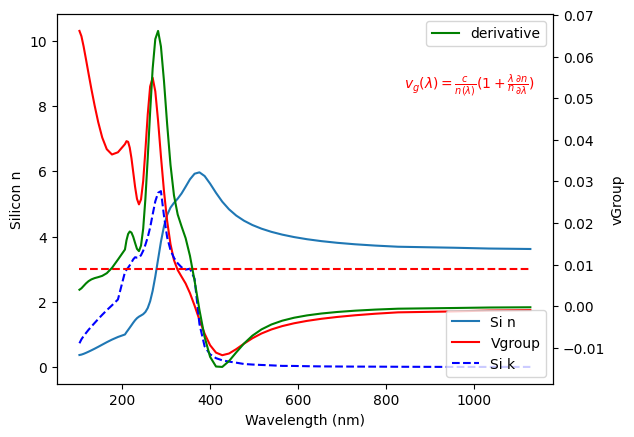

In [15]:
# calculating group velocity poorly
smoothed_si_y_n_total = gaussian_filter1d(si_y_n_total, sigma=2)
dy_dx = gaussian_filter1d(np.gradient(smoothed_si_y_n_total, si_x_n_total), sigma = 2)

c = 3.0
vPhase = c/smoothed_si_y_n_total
vGroup = vPhase + (1 + (si_x_n_total/smoothed_si_y_n_total) * dy_dx)

fig, ax1 = plt.subplots()


# Plot Si n
ax1.plot(si_x_n_total, smoothed_si_y_n_total, label="Si n")

ax2 = ax1.twinx()

ax2.plot(si_x_n_total, dy_dx, color="green", label="derivative")

ax1.plot(si_x_n_total, vGroup, color="red", label="Vgroup")
ax1.plot(si_x_k_total, si_y_k_total, color = "blue", linestyle = "--", label="Si k")

ax1.set_xlabel("Wavelength (nm)")

ax1.set_ylabel("Silicon n")
ax1.legend(loc="lower right")

ax1.text(0.7, 0.8, r'$v_g(\lambda) = \frac{c}{n(\lambda)}(1 + \frac{\lambda}{n} \frac{\partial n}{\partial \lambda})$', color = "red", transform=ax1.transAxes)
ax1.hlines(3, xmin = min(si_x_n_total), xmax = max(si_x_n_total), color="red", linestyle="--", label="c")

ax2.set_ylabel("vGroup")
ax2.legend(loc="upper right")

plt.show()


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_47475/2482921827.py:1: RuntimeWarning: divide by zero encountered in divide
  absL_si = si_x_n_total/(4*np.pi*si_y_k_total) * 1e-3 # in um
/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_47475/2482921827.py:3: RuntimeWarning: divide by zero encountered in divide
  absL_Quartz = sioX/(4*np.pi*sioK) * 1e-3 # in um


[ 8.26666667  8.55172414  8.85714286  9.18518519  9.53846154  9.92
 10.33333333 10.7826087  11.27272727] [1.19366207e+01 1.62517371e+00 7.57880681e-01 4.06930252e-01
 1.68212541e-01 3.99967187e-02 9.49328620e-03 1.44640576e-02
 1.13240904e-02]


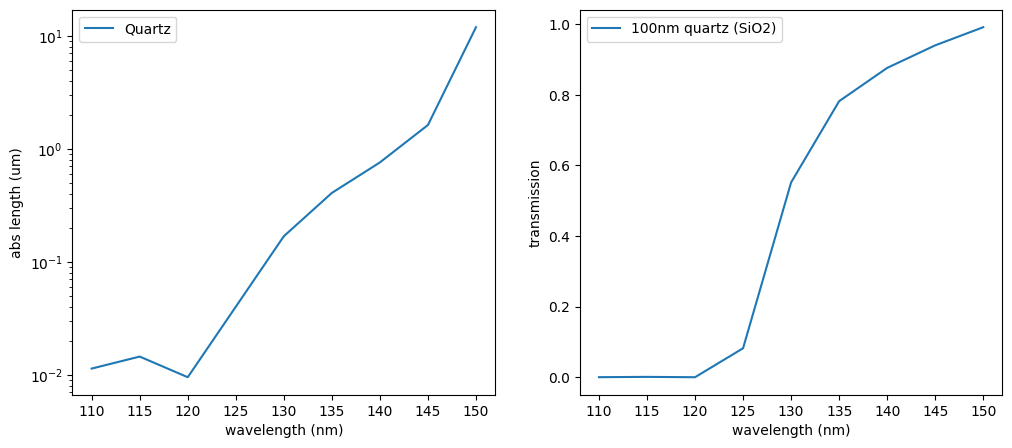

In [16]:
absL_si = si_x_n_total/(4*np.pi*si_y_k_total) * 1e-3 # in um

absL_Quartz = sioX/(4*np.pi*sioK) * 1e-3 # in um

Tfrac = lambda z, absL: 1 - np.exp(-z/absL)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.semilogy(sioX, absL_Quartz, label="Quartz")

ax1.set_xlabel("wavelength (nm)")
ax1.set_ylabel("abs length (um)")
ax1.legend()

absL_Quartz_save = absL_Quartz[np.isfinite(absL_Quartz)]
sioX_save = sioX[np.isfinite(absL_Quartz)]

absL_Quartz_eV = np.copy(absL_Quartz_save[::-1])
sioX_eV = 1240./np.copy(sioX_save[::-1])

# ax2.plot(sioX, Tfrac(1.1*1e3, absL_Quartz), label="1.1 mm quartz")
ax2.set_ylabel("transmission")
ax2.set_xlabel("wavelength (nm)")
ax2.plot(sioX_save,  np.exp(-0.1/absL_Quartz_save), label="100nm quartz (SiO2)")
ax2.legend()

print(sioX_eV, absL_Quartz_eV)

np.savetxt(os.path.join(savePath, "quartz_absLength.txt"), np.column_stack((sioX_save, absL_Quartz_save)), fmt='%.6f', delimiter='\t', header='Wavelength (nm), abs length (um), from webpage UV data \t')